# Etapa 2: Transformação numérica e redução de dimensionalidade

Nesta parte da Etapa 2 eu cuido da escala dos atributos numéricos. Parti da base limpa da Pessoa 1 (`treino_limpo.csv`) e comparei, sempre com validação cruzada e F1-macro:

1. **transformação** com `log1p` nos atributos muito assimétricos (bytes e duração, como pede o enunciado, e uma variante com todas as contagens);
2. **escala** com `StandardScaler` × `RobustScaler` (e sem escala, como referência);
3. **redução de dimensionalidade** com PCA.

Tudo fica dentro de um `Pipeline`, então o `log1p`, os escaladores e o PCA só são ajustados no treino de cada fold. As peças ficam no arquivo `transformacao.py`, para a Pessoa 4 juntar no notebook final.

## 0. Leitura dos dados e avaliação

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate

import transformacao as T   # as peças desta parte ficam em transformacao.py

pd.set_option("display.max_columns", 60)
AZUL, LARANJA, CINZA = "#2a6fdb", "#d95f02", "#8a8a8a"

PASTA = Path("BANCO_DE_DADOS")
treino = pd.read_csv(PASTA / "treino_limpo.csv")
X, y = T.separar(treino)          # tira class e score_ids_legado
NUM = T.colunas_numericas(X)

print("X:", X.shape, f"| anomalias: {y.mean() * 100:.2f}%")
print(f"{len(NUM)} numéricas e {len(T.CATEGORICAS)} categóricas")

X: (55074, 40) | anomalias: 3.30%
37 numéricas e 3 categóricas


Deixei `score_ids_legado` de fora de propósito: o grupo ainda não decidiu se ela é vazamento, e se ela for muito forte pode esconder a diferença entre as técnicas que quero comparar.

**Avaliação.** A função `avaliar(pipeline)` da Pessoa 1 ainda não está pronta, então uso uma provisória com o mesmo protocolo combinado: validação cruzada estratificada com 5 folds (embaralhada, `random_state=42`) e F1-macro. Quando a dela sair, é só trocar.

**Modelos.** Escala e PCA só fazem diferença para modelos sensíveis à escala, então comparo dois deles: **regressão logística** (linear, otimizada por gradiente) e **KNN** (baseado em distância). Árvores não mudam com transformações crescentes como essas, por isso ficaram de fora desta comparação. A imputação (mediana / mais frequente) e a codificação (one-hot) são provisórias, iguais em todas as rodadas, e serão trocadas pela escolha da Pessoa 2.

In [2]:
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# provisória, até a avaliar() da Pessoa 1 ficar pronta
def avaliar(pipeline, X=X, y=y):
    r = cross_validate(pipeline, X, y, cv=CV, scoring="f1_macro", n_jobs=-1, return_estimator=True)
    return {"f1_macro": r["test_score"].mean(), "desvio": r["test_score"].std(),
            "treino_s": r["fit_time"].mean(), "previsao_s": r["score_time"].mean(),
            "estimadores": r["estimator"]}

MODELOS = {
    "Regressão logística": lambda: LogisticRegression(max_iter=2000),
    "KNN (k=5)": lambda: KNeighborsClassifier(n_neighbors=5),
}

## 1. Por que `log1p`?

Antes de transformar, olho a assimetria (*skewness*) das numéricas. Uma distribuição simétrica tem assimetria perto de 0; acima de 1 já é bem assimétrica. O `log1p(x) = log(1 + x)` comprime os valores grandes e funciona com zero, que é o valor mais comum nessas colunas.

In [3]:
assim = X[NUM].skew()
resumo = pd.DataFrame({
    "assimetria": assim,
    "% zeros": (X[NUM] == 0).mean() * 100,
    "mediana": X[NUM].median(),
    "máximo": X[NUM].max(),
}).sort_values("assimetria", ascending=False)
resumo["log1p na variante contagens"] = resumo.index.isin(T.COLS_LOG_CONTAGENS)
display(resumo.round(2).head(20))
print("colunas 0/1:", [c for c in NUM if set(X[c].dropna().unique()) <= {0, 1}])

,assimetria,% zeros,mediana,máximo,log1p na variante contagens
is_host_login,234.68,100.00,0.0,1.0,False
dst_bytes,215.03,17.28,386.0,209228000.0,True
duration,182.59,87.48,0.0,39603000.0,True
num_root,177.83,99.20,0.0,7468.0,True
urgent,149.46,99.99,0.0,3.0,True
src_bytes,101.58,4.30,227.0,21945520.0,True
land,88.69,99.99,0.0,1.0,False
num_file_creations,65.44,94.39,0.0,100.0,True
num_shells,49.69,99.95,0.0,2.0,True
num_compromised,49.39,93.23,0.0,10300.0,True


colunas 0/1: ['land', 'logged_in', 'root_shell', 'su_attempted', 'is_host_login', 'is_guest_login']


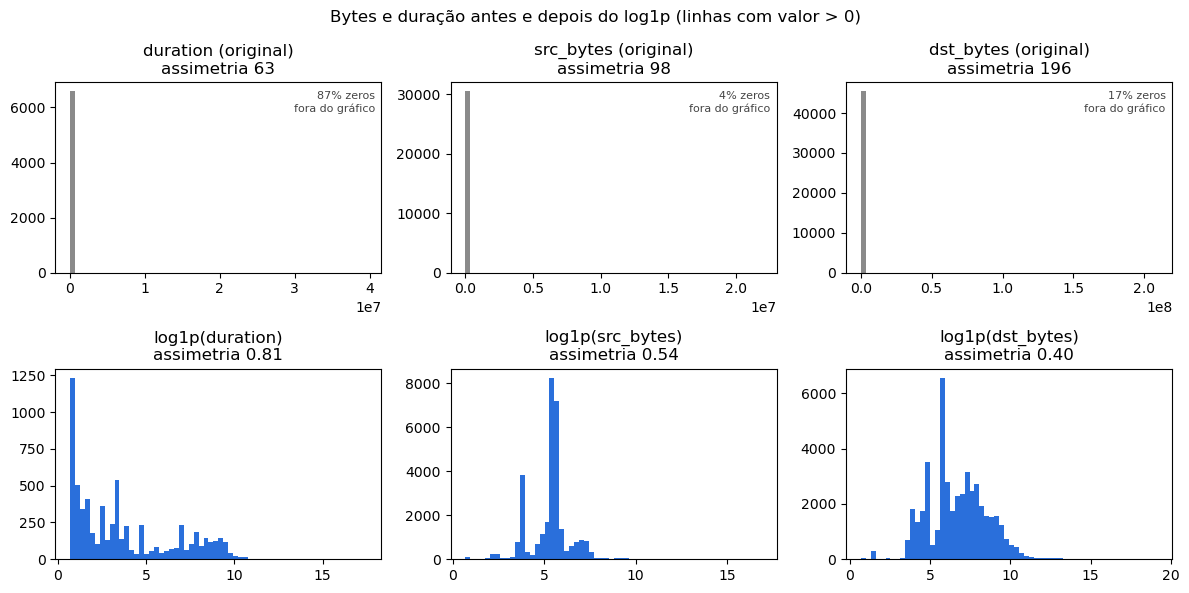

In [4]:
# gráfico 1: bytes e duração antes e depois do log1p (só valores > 0, senão o zero domina)
fig, axes = plt.subplots(2, 3, figsize=(12, 6))
for j, c in enumerate(T.COLS_LOG_BYTES):
    v = X[c].dropna()
    v = v[v > 0]
    axes[0, j].hist(v, bins=60, color=CINZA)
    axes[0, j].set_title(f"{c} (original)\nassimetria {v.skew():.0f}")
    axes[1, j].hist(np.log1p(v), bins=60, color=AZUL)
    axes[1, j].set_title(f"log1p({c})\nassimetria {np.log1p(v).skew():.2f}")
    axes[0, j].text(0.98, 0.95, f"{(X[c] == 0).mean():.0%} zeros\nfora do gráfico", transform=axes[0, j].transAxes,
                    ha="right", va="top", fontsize=8, color="#444")
fig.suptitle("Bytes e duração antes e depois do log1p (linhas com valor > 0)")
plt.tight_layout(); plt.show()

**Conclusão da seção 1**

- Os bytes e a duração estão entre as colunas mais assimétricas da base: `dst_bytes` tem assimetria 215, `duration` 183 e `src_bytes` 102. Os máximos chegam a 209 milhões de bytes e 39,6 milhões de segundos, enquanto as medianas são 386, 0 e 227.
- Olhando só os valores acima de zero, o `log1p` derruba a assimetria para menos de 1 nas três (0,81 na duração, 0,54 em `src_bytes` e 0,40 em `dst_bytes`). O gráfico mostra a diferença: antes quase tudo fica espremido numa barra perto do zero; depois aparece a distribuição de verdade.
- `duration` é zero em 87% das linhas. O `log1p` mantém o zero como zero, então essas linhas não mudam.
- Outras contagens também são muito assimétricas (`num_root`, `num_compromised`, `num_file_creations`, `hot`...). Por isso testo também uma variante com `log1p` em **todas as contagens** (16 colunas que não são taxa nem 0/1). As taxas já ficam entre 0 e 1 e as seis colunas 0/1 não têm o que comprimir, então ficam de fora.

## 2. Por que o `RobustScaler` pode não ajudar aqui

O `StandardScaler` subtrai a média e divide pelo desvio padrão. O `RobustScaler` subtrai a mediana e divide pelo intervalo interquartil (IQR = Q3 − Q1), que não é afetado por valores extremos. O problema é quando o IQR é **zero**: aí o sklearn não divide por nada (escala 1), e a coluna fica com os valores originais. Conto quantas colunas estão nessa situação.

In [5]:
q1, q3 = X[NUM].quantile(0.25), X[NUM].quantile(0.75)
iqr = q3 - q1
iqr_zero = iqr[iqr == 0].index.tolist()
print(f"{len(iqr_zero)} de {len(NUM)} numéricas têm IQR = 0")
display(pd.DataFrame({"IQR": iqr[iqr_zero], "máximo": X[iqr_zero].max()})
        .sort_values("máximo", ascending=False).head(10))

25 de 37 numéricas têm IQR = 0


,IQR,máximo
duration,0.0,39603000.0
num_compromised,0.0,10300.0
num_root,0.0,7468.0
hot,0.0,101.0
num_file_creations,0.0,100.0
num_access_files,0.0,9.0
num_failed_logins,0.0,4.0
urgent,0.0,3.0
wrong_fragment,0.0,3.0
num_shells,0.0,2.0


**Conclusão da seção 2**

- 25 das 37 numéricas têm IQR = 0, porque mais de 75% das linhas têm o mesmo valor (quase sempre zero). Nelas o `RobustScaler` só subtrai a mediana e **não muda a escala**.
- Entre elas estão justamente as colunas com valores extremos: `duration` (até 39,6 milhões), `num_compromised` (até 10.300) e `num_root` (até 7.468). Sem `log1p`, esses valores entram no modelo praticamente do jeito que vieram, e a expectativa é que o `RobustScaler` vá mal nesse caso. A seção 3 confirma.

## 3. Comparação: `log1p` × escala

Cruzo três opções de `log1p` (nenhum, só bytes e duração, todas as contagens) com três de escala (nenhuma, `StandardScaler`, `RobustScaler`), nos dois modelos. São 18 combinações, cada uma com 5 folds. O que muda entre elas é só o bloco numérico; imputação, one-hot e modelo são os mesmos.

In [6]:
OPCOES_LOG = {
    "sem log1p": [],
    "log1p bytes e duração": T.COLS_LOG_BYTES,
    "log1p todas as contagens": T.COLS_LOG_CONTAGENS,
}
ESCALAS = {"sem escala": "nenhum", "StandardScaler": "standard", "RobustScaler": "robust"}

linhas = []
for nome_m, modelo in MODELOS.items():
    for nome_log, cols in OPCOES_LOG.items():
        for nome_esc, esc in ESCALAS.items():
            pipe = Pipeline([("pre", T.montar_preprocessador(cols, esc)), ("modelo", modelo())])
            r = avaliar(pipe)
            linhas.append({"modelo": nome_m, "log1p": nome_log, "escala": nome_esc,
                           "f1_macro": r["f1_macro"], "desvio": r["desvio"], "treino_s": r["treino_s"]})
comp = pd.DataFrame(linhas)

# tabela: F1-macro médio ± desvio entre os folds
comp["F1-macro"] = comp["f1_macro"].map("{:.4f}".format) + " ± " + comp["desvio"].map("{:.4f}".format)
tabela = comp.pivot(index=["modelo", "log1p"], columns="escala", values="F1-macro")
display(tabela.loc[[(m, l) for m in MODELOS for l in OPCOES_LOG], list(ESCALAS)])

melhor = comp.loc[comp.groupby("modelo")["f1_macro"].idxmax(), ["modelo", "log1p", "escala", "f1_macro"]]
display(melhor.round(4).reset_index(drop=True))

# tempo médio de treino por fold (s) na regressão logística: sem escala o otimizador demora a convergir
display(comp[comp["modelo"] == "Regressão logística"]
        .pivot(index="log1p", columns="escala", values="treino_s").loc[list(OPCOES_LOG), list(ESCALAS)].round(1))

escala                                             sem escala  \
modelo              log1p                                       
Regressão logística sem log1p                 0.8903 ± 0.0084   
                    log1p bytes e duração     0.9314 ± 0.0043   
                    log1p todas as contagens  0.9379 ± 0.0023   
KNN (k=5)           sem log1p                 0.9003 ± 0.0052   
                    log1p bytes e duração     0.8810 ± 0.0080   
                    log1p todas as contagens  0.9511 ± 0.0078   

escala                                         StandardScaler     RobustScaler  
modelo              log1p                                                       
Regressão logística sem log1p                 0.9300 ± 0.0043  0.8436 ± 0.0363  
                    log1p bytes e duração     0.9336 ± 0.0031  0.9323 ± 0.0037  
                    log1p todas as contagens  0.9373 ± 0.0013  0.9387 ± 0.0026  
KNN (k=5)           sem log1p                 0.9512 ± 0.0065  0.9137 ± 0.0054  
                    log1p bytes e duração     0.9523 ± 0.0075  0.9235 ± 0.0078  
                    log1p todas as contagens  0.9588 ± 0.0053  0.9289 ± 0.0053

,modelo,log1p,escala,f1_macro
0,KNN (k=5),log1p todas as contagens,StandardScaler,0.9588
1,Regressão logística,log1p todas as contagens,RobustScaler,0.9387


escala,sem escala,StandardScaler,RobustScaler
log1p,,,
sem log1p,39.3,2.0,40.5
log1p bytes e duração,40.4,3.5,16.3
log1p todas as contagens,2.2,1.9,11.5


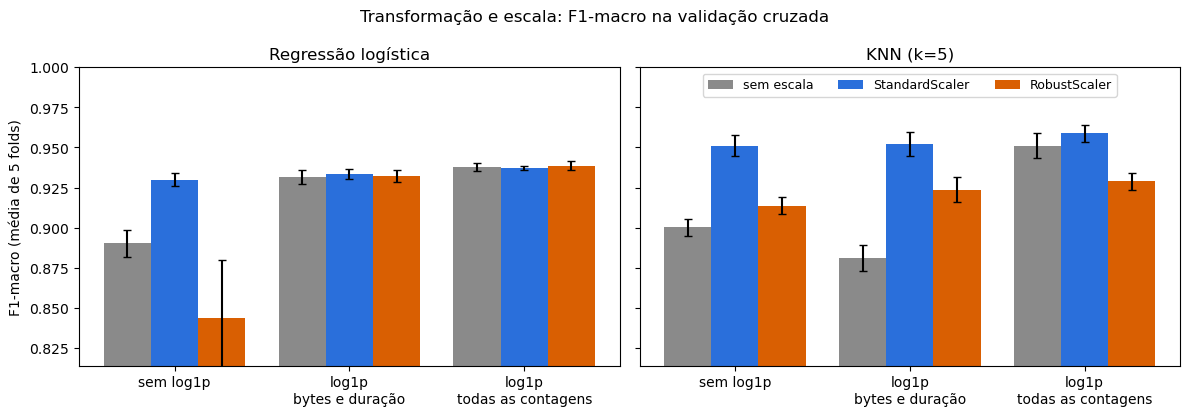

In [7]:
# gráfico 2: F1-macro de cada combinação, com o desvio entre os folds
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
cores = {"sem escala": CINZA, "StandardScaler": AZUL, "RobustScaler": LARANJA}
x = np.arange(len(OPCOES_LOG))
for ax, nome_m in zip(axes, MODELOS):
    sub = comp[comp["modelo"] == nome_m]
    for k, esc in enumerate(ESCALAS):
        s = sub[sub["escala"] == esc]
        ax.bar(x + (k - 1) * 0.27, s["f1_macro"], 0.27, yerr=s["desvio"], capsize=3, color=cores[esc], label=esc)
    ax.set_xticks(x)
    ax.set_xticklabels([n.replace("log1p ", "log1p\n") for n in OPCOES_LOG])
    ax.set_title(nome_m)
axes[0].set_ylim(comp["f1_macro"].min() - 0.03, 1)
axes[0].set_ylabel("F1-macro (média de 5 folds)")
axes[1].legend(loc="upper center", ncol=3, fontsize=9)
fig.suptitle("Transformação e escala: F1-macro na validação cruzada")
plt.tight_layout(); plt.show()

**Conclusão da seção 3**

- **O `log1p` ajudou nos dois modelos.** O melhor resultado de cada modelo usa `log1p` em todas as contagens: 0,9588 no KNN (com `StandardScaler`) e 0,9387 na regressão logística (com `RobustScaler`). Só bytes e duração já ajudam, mas a variante com todas as contagens é melhor em quase todas as combinações.
- **Sem `log1p`, o `RobustScaler` é a pior opção:** 0,8436 na regressão logística (com o maior desvio da tabela, 0,036) e 0,9137 no KNN, abaixo até de não escalar no caso da logística. É o efeito da seção 2: com IQR = 0 os valores extremos não são reduzidos. Com o `log1p` antes, os extremos já ficam pequenos e o `RobustScaler` se recupera na logística (0,9387).
- **Na regressão logística, depois do `log1p` em todas as contagens, a escala quase não importa:** 0,9379 (sem escala), 0,9373 (Standard) e 0,9387 (Robust), diferenças menores que o desvio entre os folds. A escala aparece no tempo: sem `log1p`, a logística leva cerca de 40 s por fold sem escala ou com `RobustScaler`, contra uns 2 s com `StandardScaler`, porque com valores enormes o otimizador demora a convergir. Com `log1p` em todas as contagens, sem escala e `StandardScaler` ficam em uns 2 s e o `RobustScaler` em pouco mais de 10 s (os tempos variam um pouco a cada execução).
- **No KNN a escala importa muito, e o `StandardScaler` é sempre o melhor**, cerca de 0,03 acima do `RobustScaler`. O KNN mede distâncias, e o `StandardScaler` coloca todas as colunas com desvio 1, inclusive as 25 de IQR = 0, que o `RobustScaler` deixa como estão. Sem escala, o resultado depende das unidades: com `log1p` só nos bytes ele piora (0,8810), porque aí as contagens que vão até 511 passam a dominar a distância.

**Escolha:** `log1p` em todas as contagens + `StandardScaler` (`T.montar_preprocessador(T.COLS_LOG_CONTAGENS, "standard")`). É o melhor no KNN com folga e, na logística, fica empatado com os outros dentro do desvio. É essa configuração que uso como base para o PCA na próxima seção.